In [28]:
import os 

print(os.getcwd())
os.chdir("../data/")
print(os.getcwd())


print("\nData to be curated:")
os.listdir()

/Users/caden/Desktop/psalms-text-comparison/data
/Users/caden/Desktop/psalms-text-comparison/data

Data to be curated:


['offical_psalms_data.csv',
 'psalms_with_sentiment.csv',
 'cleaned_psalm_verses.csv',
 'psalms_with_data_2.csv',
 'psalms_with_data.csv',
 'grouped_psalm.csv',
 'psalms_with_bertTopic.csv']

In [29]:
import pandas as pd 

psalms = pd.read_csv("offical_psalms_data.csv")
psalms

,Unnamed: 0,text_Psalter,psalm_num,verse,neg,neu,pos,compound,polarity,subjectivity,...,syllable_count,avg_syllables_per_word,polysyllable_count,num_sentences,avg_words_sent,kathisma_num,bertTopic,vader_category_Negative,vader_category_Neutral,vader_category_Positive
0,0,0,1,Blessed is the man Who walks not in the counse...,0.015,0.920,0.064,0.7783,0.000000,0.000000,...,163,1.225564,8,6,22.166667,1.0,0,0,0,1
1,2,0,2,Why do the nations rage And the people meditat...,0.120,0.787,0.093,-0.6486,-0.153333,0.400000,...,255,1.281407,12,12,16.583333,1.0,3,1,0,0
2,4,0,3,A psalm by David when he fled from the face of...,0.089,0.786,0.126,0.8020,0.048889,0.437778,...,183,1.220000,7,8,18.750000,1.0,1,0,0,1
3,6,0,4,For the End in psalms an ode by David You hear...,0.092,0.748,0.159,0.8919,0.178571,0.600000,...,189,1.145455,4,8,20.625000,1.0,1,0,0,1
4,8,0,5,For the End concerning the inheritance a psalm...,0.130,0.712,0.157,0.7774,0.075000,0.593750,...,309,1.245968,14,12,20.666667,1.0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
296,591,1,146,Alleluia of Aggeus and Zacharias Praise the Lo...,0.095,0.765,0.141,0.8417,0.157407,0.481481,...,232,1.260870,10,11,16.727273,20.0,2,0,0,1
297,593,1,147,Alleluia of Aggeus and Zacharias Praise the Lo...,0.000,0.794,0.206,0.9808,-0.200000,0.650000,...,156,1.300000,4,9,13.333333,20.0,-1,0,0,1
298,595,1,148,Alleluia of Aggeus and Zacharias Praise the Lo...,0.018,0.749,0.233,0.9946,0.116667,0.316667,...,258,1.277228,10,14,14.428571,20.0,2,0,0,1
299,597,1,149,Let Israel be glad in Him who made him And let...,0.017,0.759,0.224,0.9870,0.265455,0.664848,...,177,1.282609,6,9,15.333333,20.0,2,0,0,1


In [30]:
psalms.columns

Index(['Unnamed: 0', 'text_Psalter', 'psalm_num', 'verse', 'neg', 'neu', 'pos',
       'compound', 'polarity', 'subjectivity', 'emotional_score', 'fk_score',
       'gf_score', 'smog_score', 'word_count', 'avg_word_len',
       'syllable_count', 'avg_syllables_per_word', 'polysyllable_count',
       'num_sentences', 'avg_words_sent', 'kathisma_num', 'bertTopic',
       'vader_category_Negative', 'vader_category_Neutral',
       'vader_category_Positive'],
      dtype='str')

In [31]:
psalms.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               301 non-null    int64  
 1   text_Psalter             301 non-null    int64  
 2   psalm_num                301 non-null    int64  
 3   verse                    301 non-null    str    
 4   neg                      301 non-null    float64
 5   neu                      301 non-null    float64
 6   pos                      301 non-null    float64
 7   compound                 301 non-null    float64
 8   polarity                 301 non-null    float64
 9   subjectivity             301 non-null    float64
 10  emotional_score          301 non-null    float64
 11  fk_score                 285 non-null    float64
 12  gf_score                 301 non-null    float64
 13  smog_score               301 non-null    float64
 14  word_count               301 non-null

Some of the Flesch-Kincaid,`fk_score`,  scores are missing the modeling will break with any missing data. I am going to fill this column with the mean score, to mitigate this issue. 

In [32]:
psalms['fk_score'] = psalms['fk_score'].fillna(psalms['fk_score'].mean())

It seems that there is also missing data in the Kathisma numbering, `kathisma_num`, we are going to see if we can see what number is missing 



In [33]:
psalms.loc[psalms['kathisma_num'].isna(), 'kathisma_num'] = 20

In [34]:
psalms.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               301 non-null    int64  
 1   text_Psalter             301 non-null    int64  
 2   psalm_num                301 non-null    int64  
 3   verse                    301 non-null    str    
 4   neg                      301 non-null    float64
 5   neu                      301 non-null    float64
 6   pos                      301 non-null    float64
 7   compound                 301 non-null    float64
 8   polarity                 301 non-null    float64
 9   subjectivity             301 non-null    float64
 10  emotional_score          301 non-null    float64
 11  fk_score                 301 non-null    float64
 12  gf_score                 301 non-null    float64
 13  smog_score               301 non-null    float64
 14  word_count               301 non-null

There is no longer any missing data, so we can start training some models. 

--- 
# Training a Perceptron 


In [35]:
# from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score

In [36]:
X = psalms[['neg', 'neu', 'pos', 'compound', 'polarity', 'subjectivity', 'emotional_score', 'fk_score',
       'gf_score', 'smog_score', 'word_count', 'avg_word_len', 'syllable_count', 'avg_syllables_per_word', 
       'polysyllable_count', 'num_sentences', 'avg_words_sent', 'kathisma_num', 'bertTopic',
       'vader_category_Negative', 'vader_category_Neutral', 'vader_category_Positive']]

y = psalms['text_Psalter']

In [37]:
#Splitting the dataset to train data and test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [38]:
#Making a perceptron classifier
perceptron = Perceptron(max_iter=100, eta0=0.1, random_state=42)
perceptron.fit(X_train, y_train)

,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",100
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",0.1
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary `.",42


In [39]:
#Making prediction on test data
y_pred = perceptron.predict(X_test)
#Finding accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy}')

Accuracy: 0.5081967213114754


In [40]:
from sklearn.metrics import classification_report
# Generate a classification report
class_report = classification_report(y_test, y_pred)
print("Classification Report:\n", class_report)

Classification Report:
               precision    recall  f1-score   support

           0       0.51      1.00      0.67        31
           1       0.00      0.00      0.00        30

    accuracy                           0.51        61
   macro avg       0.25      0.50      0.34        61
weighted avg       0.26      0.51      0.34        61



/Users/caden/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/caden/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/caden/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [41]:
import numpy as np
from sklearn.metrics import confusion_matrix

print("Predicted classes:", np.unique(y_pred, return_counts=True))
print("Actual classes:", np.unique(y_test, return_counts=True))
print(confusion_matrix(y_test, y_pred))

Predicted classes: (array([0]), array([61]))
Actual classes: (array([0, 1]), array([31, 30]))
[[31  0]
 [30  0]]


In [42]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import classification_report

model = make_pipeline(
    StandardScaler(),
    Perceptron(max_iter=2000, tol=1e-4, random_state=42)
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.53      0.55      0.54        31
           1       0.52      0.50      0.51        30

    accuracy                           0.52        61
   macro avg       0.52      0.52      0.52        61
weighted avg       0.52      0.52      0.52        61



In [43]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import classification_report, confusion_matrix

X = psalms[[
    'neg', 'neu', 'pos', 'compound', 'polarity', 'subjectivity',
    'emotional_score', 'fk_score', 'gf_score', 'smog_score',
    'word_count', 'avg_word_len', 'syllable_count',
    'avg_syllables_per_word', 'polysyllable_count',
    'num_sentences', 'avg_words_sent', 'kathisma_num',
    'bertTopic', 'vader_category_Negative',
    'vader_category_Neutral', 'vader_category_Positive'
]]

y = psalms['text_Psalter']

# Split the data while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Impute missing values, scale features, and train
model = make_pipeline(
    SimpleImputer(strategy='mean'),
    StandardScaler(),
    Perceptron(max_iter=5000, tol=1e-4, random_state=42)
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Predicted class counts:")
print(y_pred.astype(str))
print(np.unique(y_pred, return_counts=True))

Classification Report:
              precision    recall  f1-score   support

           0       0.33      0.23      0.27        31
           1       0.40      0.53      0.46        30

    accuracy                           0.38        61
   macro avg       0.37      0.38      0.36        61
weighted avg       0.37      0.38      0.36        61

Confusion Matrix:
[[ 7 24]
 [14 16]]
Predicted class counts:
['1' '1' '1' '1' '0' '1' '1' '0' '1' '1' '1' '1' '1' '1' '1' '0' '0' '0'
 '0' '0' '1' '1' '0' '1' '0' '0' '0' '0' '1' '0' '1' '1' '0' '1' '1' '1'
 '1' '1' '1' '0' '1' '1' '1' '0' '1' '0' '1' '1' '1' '1' '1' '0' '1' '1'
 '1' '0' '1' '0' '0' '1' '1']
(array([0, 1]), array([21, 40]))


In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

log_model = make_pipeline(
    SimpleImputer(strategy='mean'),
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=42)
)

log_model.fit(X_train, y_train)
log_pred = log_model.predict(X_test)

print(classification_report(y_test, log_pred, zero_division=0))
print(confusion_matrix(y_test, log_pred))

              precision    recall  f1-score   support

           0       0.28      0.23      0.25        31
           1       0.33      0.40      0.36        30

    accuracy                           0.31        61
   macro avg       0.31      0.31      0.31        61
weighted avg       0.31      0.31      0.31        61

[[ 7 24]
 [18 12]]


--- 
# Being more Selective with Features

Myabe using all possible data is not the best approach for modeling. lets look at the best correlations to use. We are going to use the `Perceptron Model` as a base line for now for comparisons. This was the best model over all. 

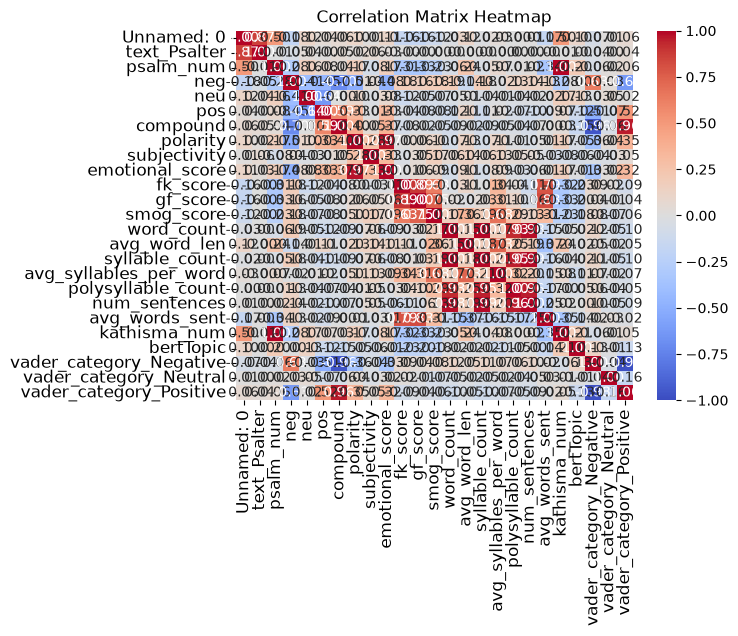

In [45]:
import seaborn as sns 
import matplotlib.pyplot as plt

corr = psalms.corr(numeric_only=True)#['berTopic']

sns.heatmap(
    corr, 
    annot=True,          # Show the correlation coefficients inside the blocks
    cmap='coolwarm',     # Red for positive correlation, blue for negative correlation
    fmt=".2f",           # Round the values to 2 decimal places
    vmin=-1, vmax=1     # Fix the colorbar limits from -1 to 1
)


# Force the title and axis tick labels to font size 12
plt.title('Correlation Matrix Heatmap', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.show()

In [128]:
correlations = corr['text_Psalter'].sort_values(key=abs, ascending=False)

correlations = pd.DataFrame(correlations)
correlations = correlations[2:]
correlations

,text_Psalter
subjectivity,0.061269
compound,0.052096
neg,-0.048042
vader_category_Negative,-0.040204
vader_category_Positive,0.039649
neu,0.038962
emotional_score,0.027373
polarity,0.021135
psalm_num,-0.005754
kathisma_num,-0.005256


We are going to refer to `correlations` to pull the **Top N** features for each trial. 

In [129]:
# The predictor Y is never going to change
y = psalms['text_Psalter']

In [142]:
def perceptron_trial(n=2):

    features = correlations[:n].index.tolist()
    X = psalms[features]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    perceptron = Perceptron(max_iter=100, eta0=0.1, random_state=42)
    perceptron.fit(X_train, y_train)

    y_pred = perceptron.predict(X_test)

    class_report = classification_report(
        y_test, y_pred, output_dict=True, zero_division=0
    )

    # Extract accuracy
    accuracy = class_report.pop("accuracy")

    # Convert remaining metrics into a DataFrame
    report_df = pd.DataFrame(class_report).T

    # Add accuracy as a column
    report_df["accuracy"] = accuracy
    report_df["features_used"] = str(features)
    report_df["n_features"] = n

    return report_df


result_df = perceptron_trial(n=2)
display(result_df)

,precision,recall,f1-score,support,accuracy,features_used,n_features
0,0.508197,1.000000,0.673913,31.0,0.508197,"['subjectivity', 'compound']",2
1,0.000000,0.000000,0.000000,30.0,0.508197,"['subjectivity', 'compound']",2
macro avg,0.254098,0.500000,0.336957,61.0,0.508197,"['subjectivity', 'compound']",2
weighted avg,0.258264,0.508197,0.342480,61.0,0.508197,"['subjectivity', 'compound']",2


## Classification Report Definitions

### Classes

- **Class 0 (Bible):** Represents Psalms from the Bible text tradition, where `text_Psalter = 0`.
- **Class 1 (Psalter):** Represents Psalms from the Psalter text tradition, where `text_Psalter = 1`.

### Evaluation Metrics

- **Precision:** The proportion of predictions for a class that were correct. For example, class 1 precision measures how many Psalter predictions were actually Psalter texts.

- **Recall:** The proportion of actual instances of a class that the model correctly identified. For example, class 1 recall measures how many actual Psalter texts the model correctly classified.

- **F1-score:** The harmonic mean of precision and recall. It balances both metrics, providing a single measure of classification performance.

- **Support:** The number of actual instances of each class in the evaluation dataset.

### Aggregate Metrics

- **Accuracy:** The proportion of all predictions that the model classified correctly.

- **Macro Average:** The unweighted average of a metric across all classes. Each class contributes equally, regardless of how many examples it contains.

- **Weighted Average:** The average of a metric across all classes, weighted by each class's support. Classes with more examples contribute more to the result.


In [143]:
len(correlations)

23

In [144]:
results = []

for n in range(1, len(correlations)+1):
    report_df = perceptron_trial(n=n)
    report_df["class"] = report_df.index
    results.append(report_df.reset_index(drop=True))

results_df = pd.concat(results, ignore_index=True)

display(results_df)

,precision,recall,f1-score,support,accuracy,features_used,n_features,class
0,0.000000,0.000000,0.000000,31.0,0.475410,['subjectivity'],1,0
1,0.483333,0.966667,0.644444,30.0,0.475410,['subjectivity'],1,1
2,0.241667,0.483333,0.322222,61.0,0.475410,['subjectivity'],1,macro avg
3,0.237705,0.475410,0.316940,61.0,0.475410,['subjectivity'],1,weighted avg
4,0.508197,1.000000,0.673913,31.0,0.508197,"['subjectivity', 'compound']",2,0
...,...,...,...,...,...,...,...,...
87,0.241870,0.491803,0.324266,61.0,0.491803,"['subjectivity', 'compound', 'neg', 'vader_cat...",22,weighted avg
88,0.000000,0.000000,0.000000,31.0,0.491803,"['subjectivity', 'compound', 'neg', 'vader_cat...",23,0
89,0.491803,1.000000,0.659341,30.0,0.491803,"['subjectivity', 'compound', 'neg', 'vader_cat...",23,1
90,0.245902,0.500000,0.329670,61.0,0.491803,"['subjectivity', 'compound', 'neg', 'vader_cat...",23,macro avg


### Graphing the results to understand 

- Using `macro avg` as a baseline of the model's overall preformance
- **X** = Using `n_features` to to track the best n-top-features that makes the model the best.
- **Y** = Using `f1-score` as it represents both `precision` and `recall` well. 

In [145]:
# filtering for only the 'macro avg' rows
macro_avgs = results_df[results_df['class'] == "macro avg"]

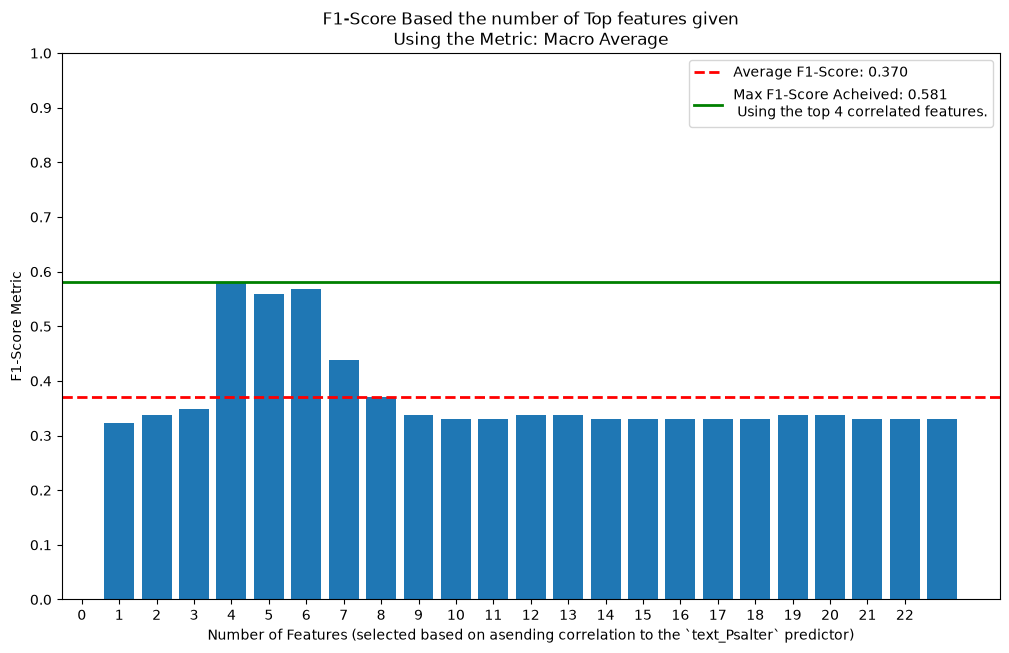

In [146]:
def plot_metric(data, metric):
    x = data['n_features']
    y = data['f1-score']

    # Create bar chart
    plt.figure(figsize=(10, 6))
    plt.bar(x, y)

       
    # Calculate average F1-score
    avg_f1 = y.mean()
    
    # Calculate max F1-score
    max_f1 = y.max()

    # Get the row with the maximum F1-score
    best_row = data.loc[y.idxmax()]

    # Get the number of features used
    best_n_features = best_row['n_features']
    
    # Add red dashed average line
    plt.axhline(
        y=avg_f1,
        color='red',
        linestyle='--',
        linewidth=2,
        label=f'Average F1-Score: {avg_f1:.3f}'
    )
    
    # Add green solid max line
    plt.axhline(
        y=max_f1,
        color='green',
        linestyle='-',
        linewidth=2,
        label=f'Max F1-Score Acheived: {max_f1:.3f} \n Using the top {best_n_features} correlated features.'
    )
    
    plt.xticks(np.arange(0, len(correlations)), ha="center")
    plt.tight_layout()

    plt.ylim(0, 1.0)
    plt.yticks(np.arange(0, 1.1, 0.1))  # Step = 0.1
    
    # Labels and title
    plt.xlabel("Number of Features (selected based on asending correlation to the `text_Psalter` predictor)")
    plt.ylabel("F1-Score Metric")
    plt.title("F1-Score Based the number of Top features given" + f"\nUsing the Metric: {metric}" +
                 "")


    # Display chart
    plt.legend()
    plt.show()
    
plot_metric(macro_avgs, "Macro Average")



## Old Graph: 
![old_psalter_class](images/bible_class_old.png)

---

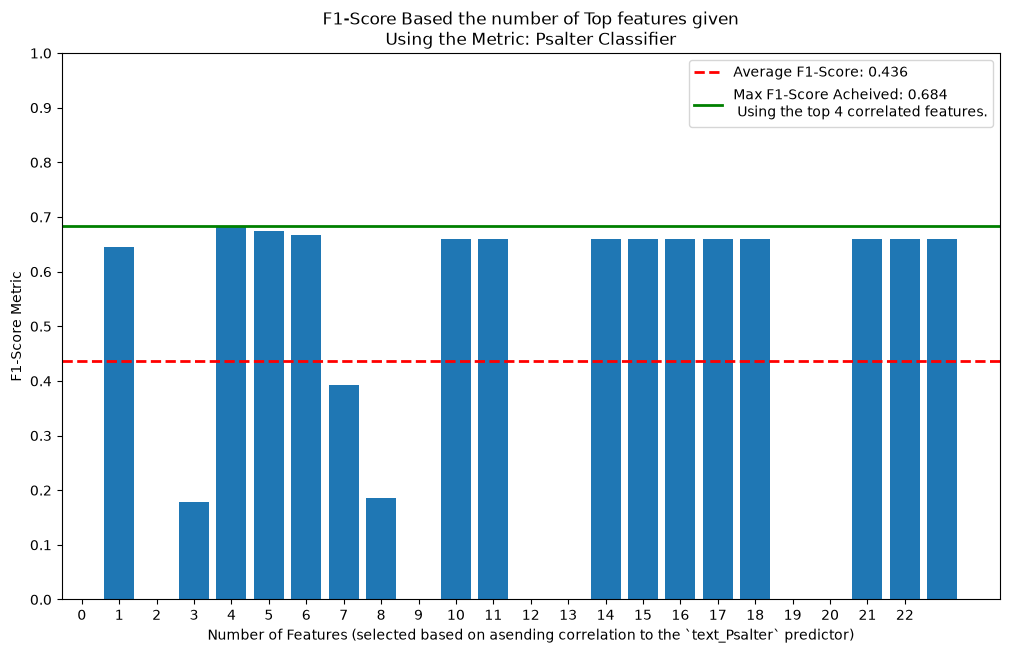

In [147]:
# filtering for only the 'macro avg' rows
psalter_class = results_df[results_df['class'] == "1"] # Psalter classifier

plot_metric(psalter_class, "Psalter Classifier")



## Old Graph: 
![old_psalter_class](images/psalter_class_old.png)

---

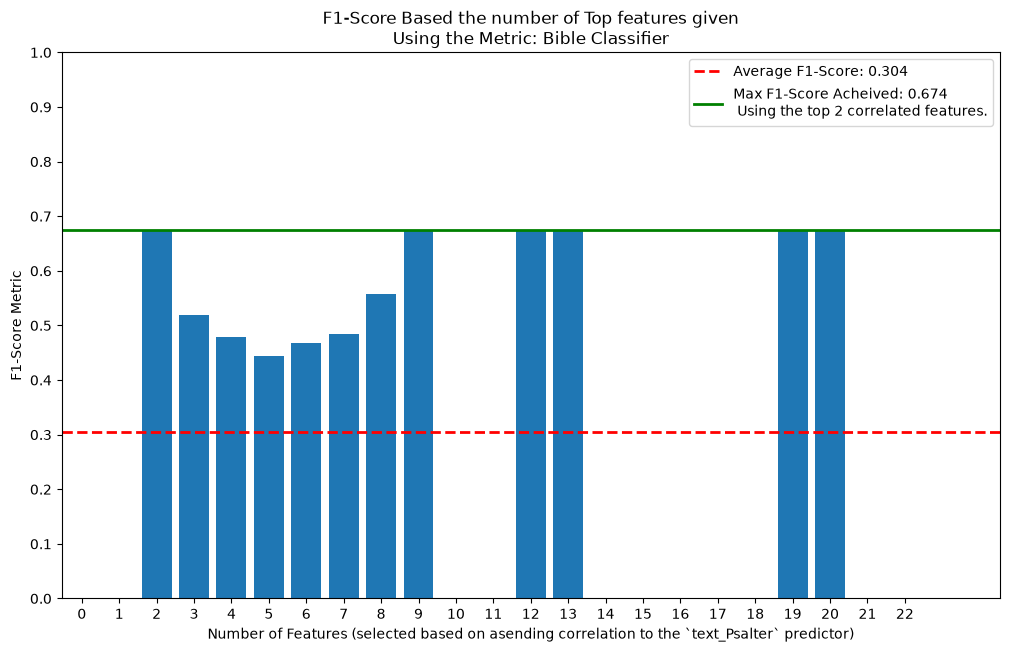

In [148]:
# filtering for only the 'macro avg' rows
bible_class = results_df[results_df['class'] == "0"] # Bible classifier

plot_metric(bible_class, "Bible Classifier")



## Old Graph: 
![old_psalter_class](images/bible_class_old.png)

---

---
## Investigating the Top 5 Correlated Features

It seems a though the top 5 correlated features to `text_psalter`. I can look further into these and determine if there is fine tuning that can be done to improve the model. 

In [149]:
target_features = correlations[:5].index.tolist() # the top 5 correlated features
predictor = ['text_Psalter'] # the column we are trying to classify from 

target_df = pd.concat([psalms[predictor], psalms[target_features]], axis=1)

In [150]:
import itertools 

# Your starting point
target_features = correlations[:5].index.tolist() 

feature_combinations = [
    list(combo) # or np.array(combo) if your downstream pipeline strictly requires NumPy arrays
    for r in range(1, len(target_features) + 1)
    for combo in itertools.combinations(target_features, r)
]

print(f'Number of Combinations: {len(feature_combinations)}')

feature_combinations

Number of Combinations: 31


[['subjectivity'],
 ['compound'],
 ['neg'],
 ['vader_category_Negative'],
 ['vader_category_Positive'],
 ['subjectivity', 'compound'],
 ['subjectivity', 'neg'],
 ['subjectivity', 'vader_category_Negative'],
 ['subjectivity', 'vader_category_Positive'],
 ['compound', 'neg'],
 ['compound', 'vader_category_Negative'],
 ['compound', 'vader_category_Positive'],
 ['neg', 'vader_category_Negative'],
 ['neg', 'vader_category_Positive'],
 ['vader_category_Negative', 'vader_category_Positive'],
 ['subjectivity', 'compound', 'neg'],
 ['subjectivity', 'compound', 'vader_category_Negative'],
 ['subjectivity', 'compound', 'vader_category_Positive'],
 ['subjectivity', 'neg', 'vader_category_Negative'],
 ['subjectivity', 'neg', 'vader_category_Positive'],
 ['subjectivity', 'vader_category_Negative', 'vader_category_Positive'],
 ['compound', 'neg', 'vader_category_Negative'],
 ['compound', 'neg', 'vader_category_Positive'],
 ['compound', 'vader_category_Negative', 'vader_category_Positive'],
 ['neg', '

In [162]:
def perceptron_trial(features):

    X = psalms[features]
    n = len(features) # documenting the number of features used. 
    
    y = psalms['text_Psalter']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    perceptron = Perceptron(max_iter=100, eta0=0.1, random_state=42)
    perceptron.fit(X_train, y_train)

    # Make predictions
    y_pred = perceptron.predict(X_test)

    # Generate classification report as a dictionary
    class_report = classification_report(
        y_test, y_pred, output_dict=True, zero_division=0
    )

    
    # Extract accuracy
    accuracy = class_report.pop("accuracy")

    # Convert remaining metrics into a DataFrame
    report_df = pd.DataFrame(class_report).T

    # Add accuracy as a column
    report_df["accuracy"] = accuracy
    report_df["features_used"] = str(features)
    report_df["n_features"] = n

    return report_df



There are **31** combinations being ran through the preceptron. Each Trial appending 5 rows of data to the dataframe. We should end up with: 

$$
31\ features\  * 4\ new\ rows = \mathbf{124\ total\_rows}
$$

In [164]:
new_results = []

for feature_set in feature_combinations: 
    new_data = perceptron_trial(feature_set)
    new_data["class"] = new_data.index
    new_results.append(new_data.reset_index(drop=True))

results_df = pd.concat(new_results, ignore_index=True)

display(results_df)
#perceptron_trial()

,precision,recall,f1-score,support,accuracy,features_used,n_features,class
0,0.000000,0.000000,0.000000,31.0,0.475410,['subjectivity'],1,0
1,0.483333,0.966667,0.644444,30.0,0.475410,['subjectivity'],1,1
2,0.241667,0.483333,0.322222,61.0,0.475410,['subjectivity'],1,macro avg
3,0.237705,0.475410,0.316940,61.0,0.475410,['subjectivity'],1,weighted avg
4,0.692308,0.290323,0.409091,31.0,0.573770,['compound'],1,0
...,...,...,...,...,...,...,...,...
119,0.652141,0.590164,0.548903,61.0,0.590164,"['compound', 'neg', 'vader_category_Negative',...",4,weighted avg
120,0.714286,0.322581,0.444444,31.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",5,0
121,0.553191,0.866667,0.675325,30.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",5,1
122,0.633739,0.594624,0.559885,61.0,0.590164,"['subjectivity', 'compound', 'neg', 'vader_cat...",5,macro avg


## The head of the Old `results_df` above: 

|   | precision | recall   | f1-score | support   | accuracy | features_used    | n_features | class        |
|---|-----------|----------|----------|-----------|----------|------------------|------------|--------------|
| 0 | 0.000000  | 0.000000 | 0.000000 | 31.000000 | 0.475410 | ['subjectivity'] | 1          | 0            |
| 1 | 0.483333  | 0.966667 | 0.644444 | 30.000000 | 0.475410 | ['subjectivity'] | 1          | 1            |
| 3 | 0.241667  | 0.483333 | 0.322222 | 61.000000 | 0.475410 | ['subjectivity'] | 1          | macro avg    |
| 4 | 0.237705  | 0.475410 | 0.316940 | 61.000000 | 0.475410 | ['subjectivity'] | 1          | weighted avg |

### Updating the Graping to adjsut to showing at most 5 features

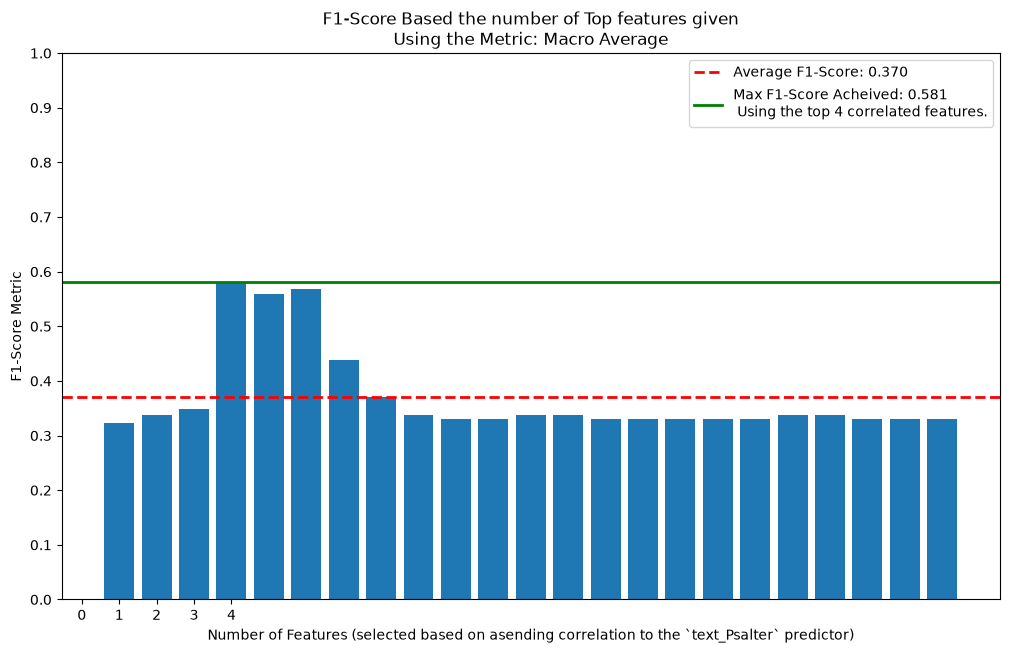

In [170]:
def plot_metric(data, metric):
    x = data['n_features']
    y = data['f1-score']

    # Create bar chart
    plt.figure(figsize=(10, 6))
    plt.bar(x, y)

       
    # Calculate average F1-score
    avg_f1 = y.mean()
    
    # Calculate max F1-score
    max_f1 = y.max()

    # Get the row with the maximum F1-score
    best_row = data.loc[y.idxmax()]

    # Get the number of features used
    best_n_features = best_row['n_features']
    
    # Add red dashed average line
    plt.axhline(
        y=avg_f1,
        color='red',
        linestyle='--',
        linewidth=2,
        label=f'Average F1-Score: {avg_f1:.3f}'
    )
    
    # Add green solid max line
    plt.axhline(
        y=max_f1,
        color='green',
        linestyle='-',
        linewidth=2,
        label=f'Max F1-Score Acheived: {max_f1:.3f} \n Using the top {best_n_features} correlated features.'
    )
    
    plt.xticks(np.arange(0, 5), ha="center")
    plt.tight_layout()

    plt.ylim(0, 1.0)
    plt.yticks(np.arange(0, 1.1, 0.1))  # Step = 0.1
    
    # Labels and title
    plt.xlabel("Number of Features (selected based on asending correlation to the `text_Psalter` predictor)")
    plt.ylabel("F1-Score Metric")
    plt.title("F1-Score Based the number of Top features given" + f"\nUsing the Metric: {metric}" +
                 "")


    # Display chart
    plt.legend()
    plt.show()
    
plot_metric(macro_avgs, "Macro Average")

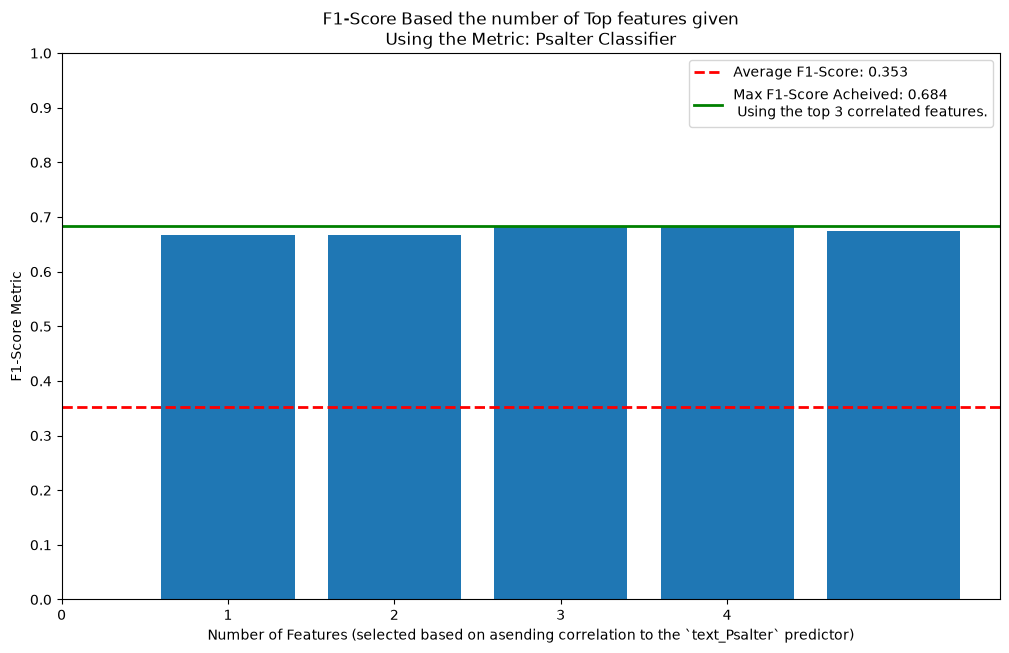

In [171]:
# filtering for only the 'macro avg' rows
psalter_class = results_df[results_df['class'] == "1"] # Psalter classifier

plot_metric(psalter_class, "Psalter Classifier")

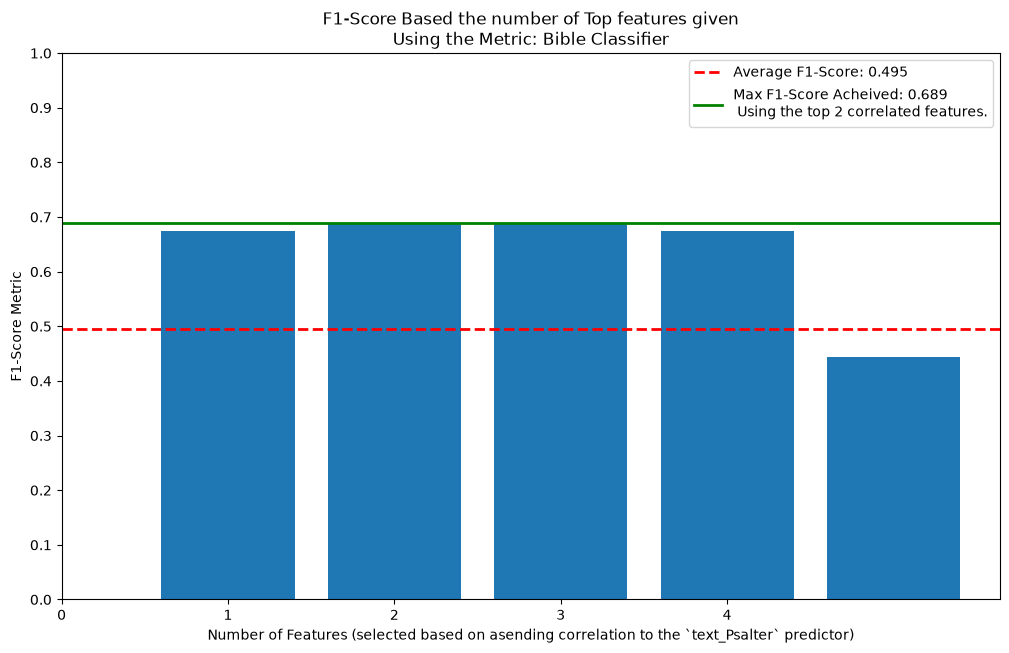

In [167]:
# filtering for only the 'macro avg' rows
bible_class = results_df[results_df['class'] == "0"] # Psalter classifier

plot_metric(bible_class, "Bible Classifier")

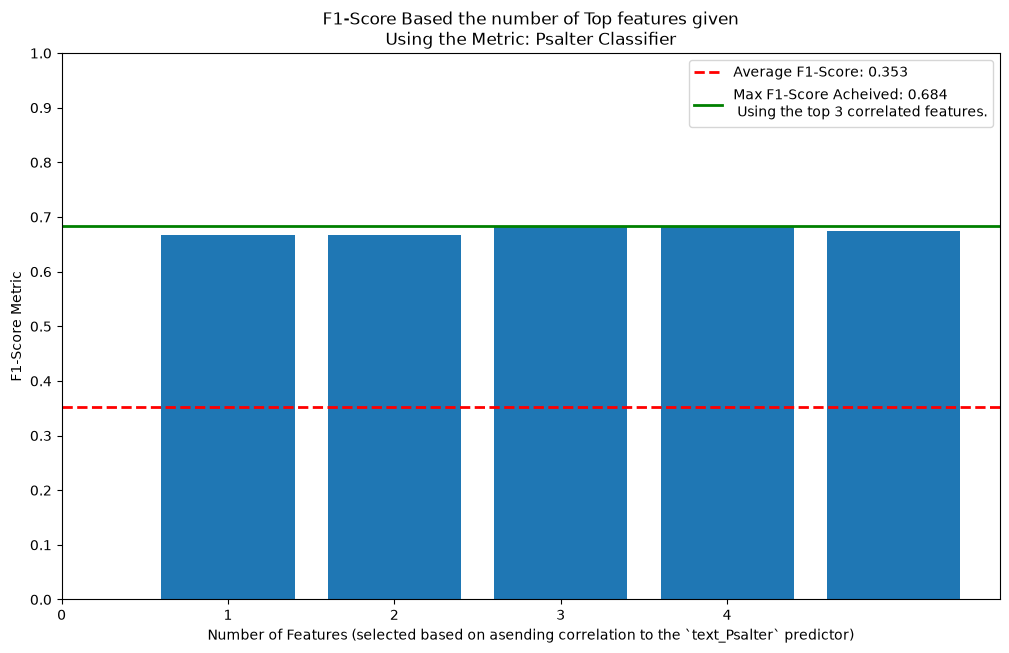

In [168]:
# filtering for only the 'macro avg' rows
psalter_class = results_df[results_df['class'] == "1"] # Psalter classifier

plot_metric(psalter_class, "Psalter Classifier")

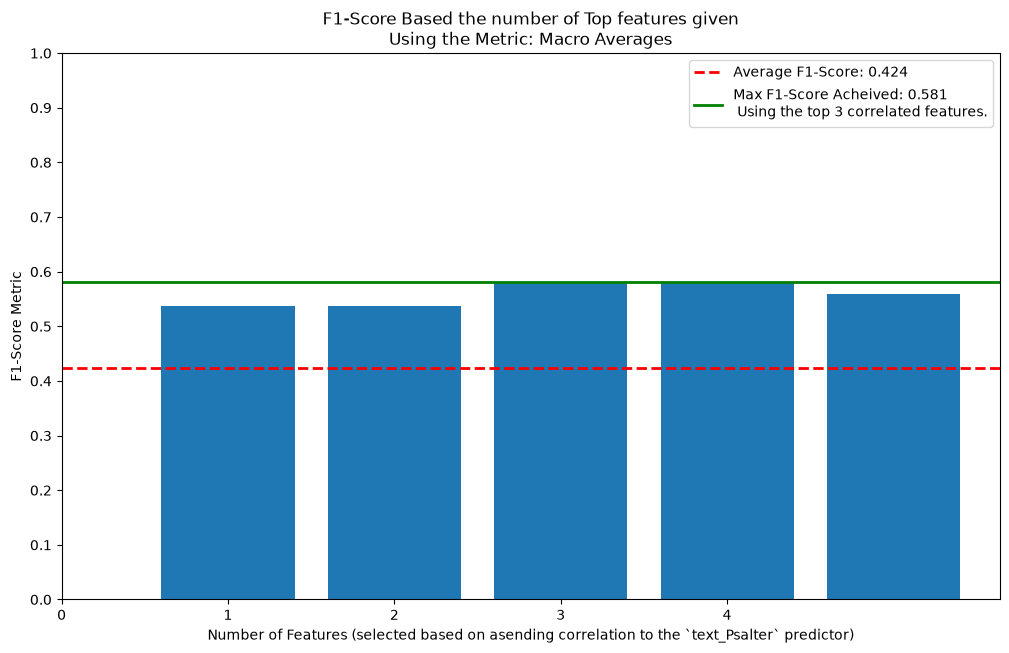

In [169]:
# filtering for only the 'macro avg' rows
mac_avgs = results_df[results_df['class'] == "macro avg"] # Psalter classifier

plot_metric(mac_avgs, "Macro Averages")

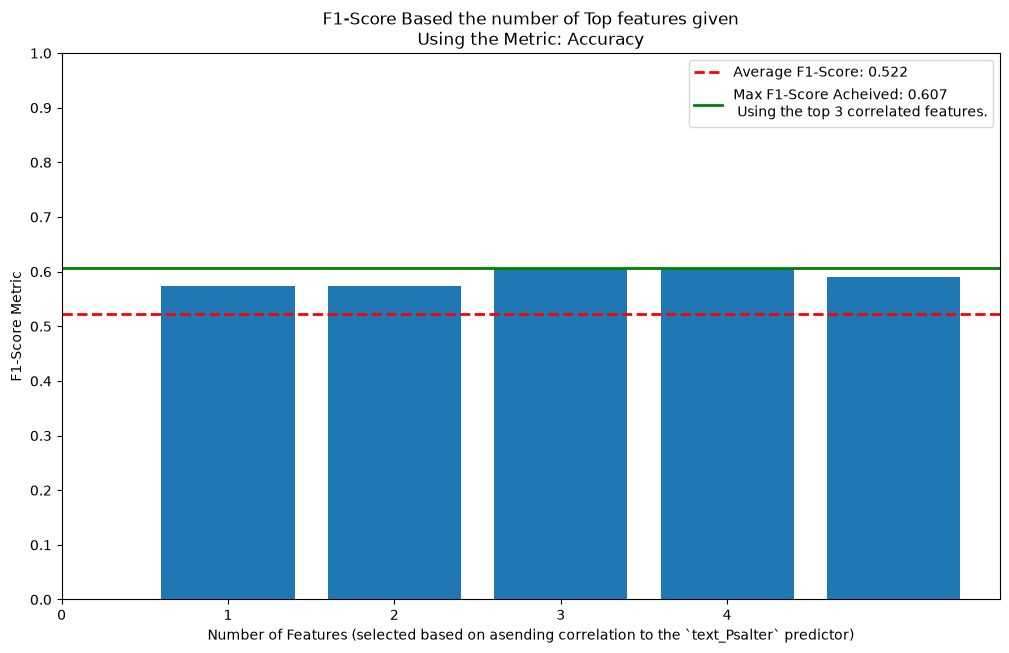

In [158]:
# filtering for only the 'macro avg' rows
accuracy = results_df[results_df['class'] == "accuracy"]# Psalter classifier

plot_metric(accuracy, "Accuracy")

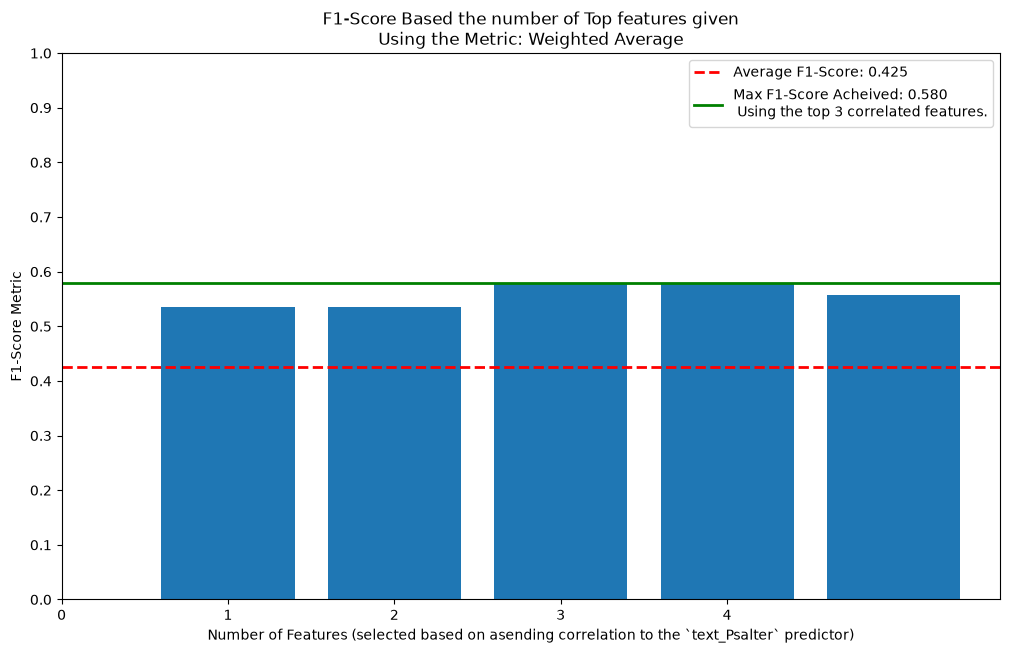

In [159]:
## filtering for only the 'macro avg' rows
w_average = results_df[results_df['class'] == "weighted avg"]# Psalter classifier

plot_metric(w_average, "Weighted Average")

---
# Looking into the specifics of the Perctron model

In [200]:
def perceptron_trial(features):

    # Select features and target
    X = psalms[features]
    y = psalms["text_Psalter"]
    n = len(features)

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # Train model
    perceptron = Perceptron(max_iter=100, eta0=0.1, random_state=42)
    perceptron.fit(X_train, y_train)

    # Predict
    y_pred = perceptron.predict(X_test)

    # Classification metrics
    class_report = classification_report(
        y_test, y_pred, output_dict=True, zero_division=0
    )
    
    accuracy = class_report.pop("accuracy")

    report_df = pd.DataFrame(class_report).T

    report_df = report_df.rename(index={
        "macro avg": "Mac_avg",
        "weighted avg": "weighted_avg"
    })

    report_df.index = report_df.index.map(str)

    report_df = report_df.reindex([
        "0", "1", "Mac_avg", "weighted_avg"
    ])

    # Convert index to a regular column
    report_df = report_df.reset_index(names="class")

    report_df["accuracy"] = accuracy
    report_df["features_used"] = str(features)
    report_df["n_features"] = n

    # Extract coefficients using the exact training feature names
    coef_df = pd.DataFrame(
        perceptron.coef_,
        columns=X_train.columns,
        index=perceptron.classes_ if perceptron.coef_.shape[0] > 1
        else ["decision_function"]
    )

    return report_df, coef_df, perceptron

In [201]:
# full dataFrames
full_results_df = pd.DataFrame()
full_coef_df = pd.DataFrame()

for i in range(len(correlations)):
    features = correlations[:i+1].index.tolist()

    result_df, coef_df, perceptron = perceptron_trial(features)

    #storing the results
    full_results_df = pd.concat([full_results_df, result_df], ignore_index=True)
    full_coef_df = pd.concat([full_coef_df, coef_df], ignore_index=False)

display(full_results_df)
display(full_coef_df)

,class,precision,recall,f1-score,support,accuracy,features_used,n_features
0,0,0.000000,0.000000,0.000000,31.0,0.475410,['subjectivity'],1
1,1,0.483333,0.966667,0.644444,30.0,0.475410,['subjectivity'],1
2,Mac_avg,0.241667,0.483333,0.322222,61.0,0.475410,['subjectivity'],1
3,weighted_avg,0.237705,0.475410,0.316940,61.0,0.475410,['subjectivity'],1
4,0,0.508197,1.000000,0.673913,31.0,0.508197,"['subjectivity', 'compound']",2
...,...,...,...,...,...,...,...,...
87,weighted_avg,0.241870,0.491803,0.324266,61.0,0.491803,"['subjectivity', 'compound', 'neg', 'vader_cat...",22
88,0,0.000000,0.000000,0.000000,31.0,0.491803,"['subjectivity', 'compound', 'neg', 'vader_cat...",23
89,1,0.491803,1.000000,0.659341,30.0,0.491803,"['subjectivity', 'compound', 'neg', 'vader_cat...",23
90,Mac_avg,0.245902,0.500000,0.329670,61.0,0.491803,"['subjectivity', 'compound', 'neg', 'vader_cat...",23


,subjectivity,compound,neg,vader_category_Negative,vader_category_Positive,neu,emotional_score,polarity,psalm_num,kathisma_num,...,syllable_count,pos,num_sentences,fk_score,polysyllable_count,avg_words_sent,bertTopic,smog_score,vader_category_Neutral,gf_score
decision_function,0.129367,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,0.054957,0.05604,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,0.029702,-0.06127,0.0880,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,0.119579,0.19799,0.0741,0.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,0.157895,0.17121,0.1331,-0.1,-2.775558e-17,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,0.144056,0.24220,0.0098,0.0,0.000000e+00,-0.1393,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,0.310887,0.07785,0.0156,0.1,-1.000000e-01,-0.0738,-0.123129,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,0.123962,0.00251,0.0589,0.1,-2.000000e-01,-0.0450,0.078061,-0.202242,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,2.434360,0.73972,0.1596,0.6,-4.000000e-01,-0.4178,0.631781,0.448854,-4.2,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
decision_function,0.990053,0.04736,-0.0051,-0.1,-5.000000e-01,-0.9121,0.364412,0.272418,9.8,2.300000e+00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


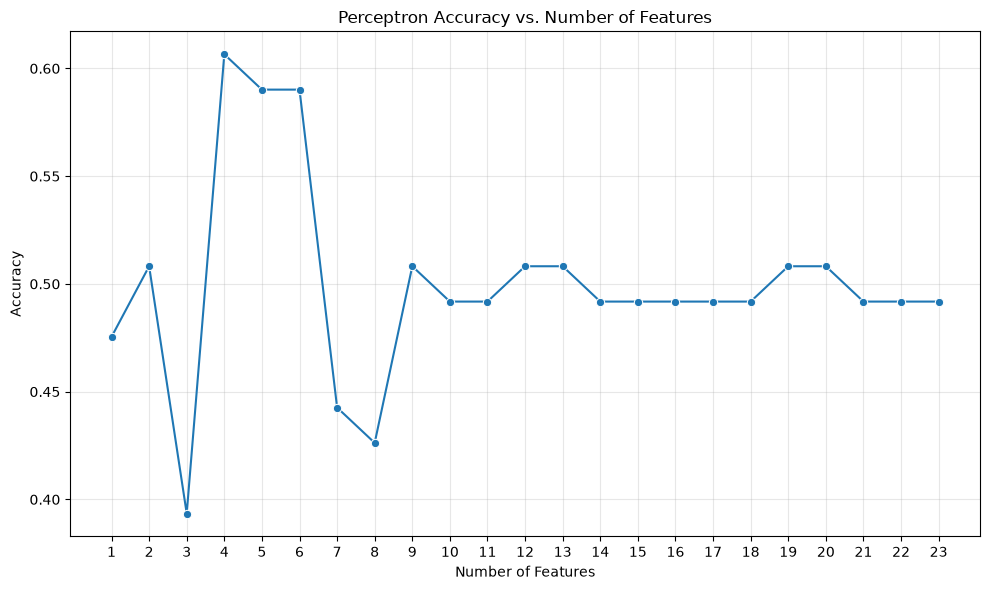

In [193]:
import matplotlib.pyplot as plt
import seaborn as sns

# If all_results has multiple classification-report rows per trial,
# keep one row per trial.
plot_df = full_results_df.drop_duplicates(
    subset=["features_used", "n_features"]
).sort_values("n_features")

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=plot_df,
    x="n_features",
    y="accuracy",
    marker="o"
)

plt.xlabel("Number of Features")
plt.ylabel("Accuracy")
plt.title("Perceptron Accuracy vs. Number of Features")
plt.xticks(sorted(plot_df["n_features"].unique()))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [202]:
# For the coefficients from one trial
weights = coef_df.iloc[0].sort_values()
weights

avg_words_sent            -18.134149
psalm_num                 -16.900000
num_sentences              -8.700000
gf_score                   -7.943769
fk_score                   -6.395020
smog_score                 -6.083018
avg_word_len               -5.680951
avg_syllables_per_word     -1.693492
vader_category_Positive    -1.400000
neu                        -0.983000
kathisma_num               -0.800000
compound                   -0.491160
pos                        -0.241600
neg                        -0.079800
vader_category_Neutral      0.000000
vader_category_Negative     0.100000
emotional_score             0.697662
subjectivity                0.735464
polarity                    0.791111
bertTopic                   2.200000
polysyllable_count          3.500000
syllable_count             51.300000
word_count                 60.300000
Name: decision_function, dtype: float64

In [219]:
# Get coefficients for one trial and sort them
weights = coef_df.iloc[0].sort_values()

# Convert correlations DataFrame to a Series
corr_series = correlations["text_Psalter"]

# Match correlations to coefficients by feature name
weights_df = pd.DataFrame({
    "perceptron_coefficient": weights,
    "correlation": corr_series.reindex(weights.index)
})

display(weights_df)

,perceptron_coefficient,correlation
avg_words_sent,-18.134149,0.000626
psalm_num,-16.900000,-0.005754
num_sentences,-8.700000,0.001832
gf_score,-7.943769,-0.000006
fk_score,-6.395020,-0.001528
smog_score,-6.083018,-0.000286
avg_word_len,-5.680951,-0.003822
avg_syllables_per_word,-1.693492,-0.003047
vader_category_Positive,-1.400000,0.039649
neu,-0.983000,0.038962


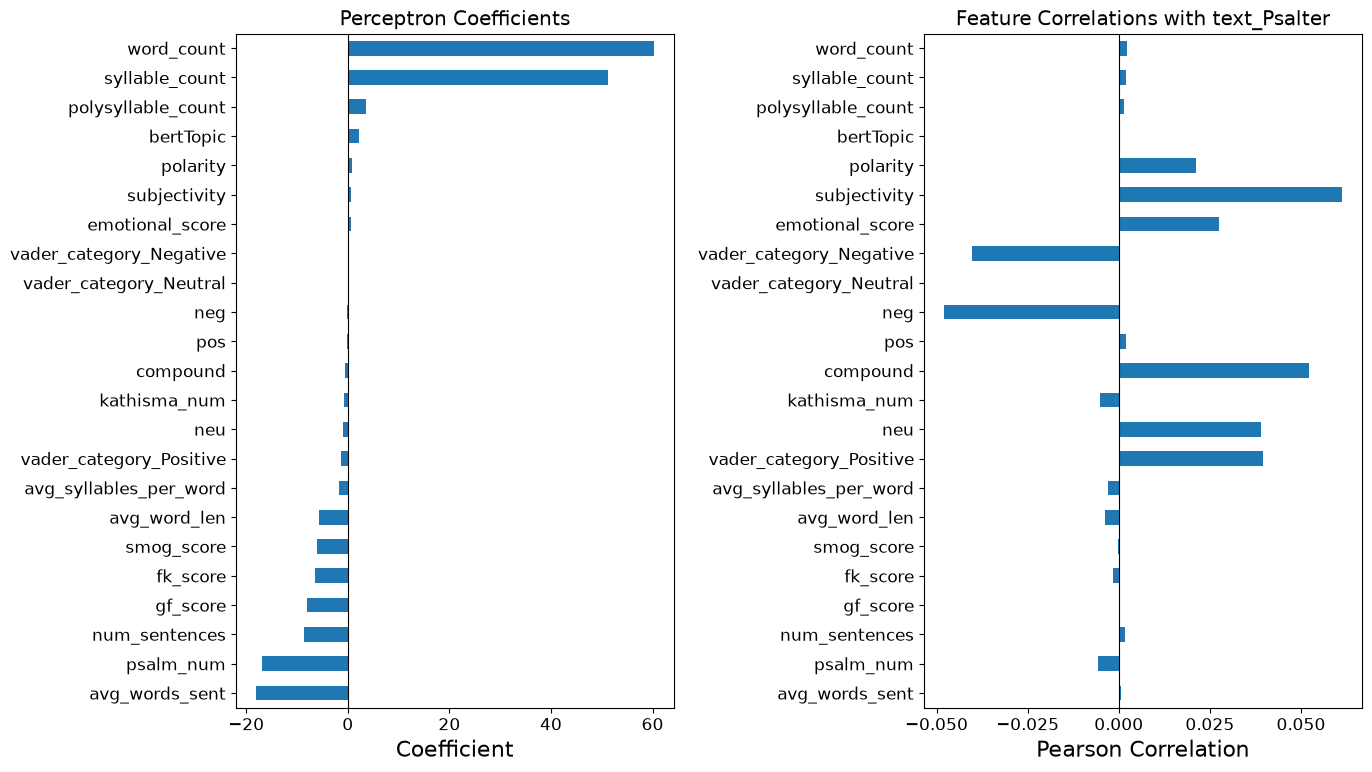

In [225]:
import matplotlib.pyplot as plt

weights_df = weights_df.sort_values("perceptron_coefficient")

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

weights_df["perceptron_coefficient"].plot(
    kind="barh", ax=axes[0], title="Perceptron Coefficients"
)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Coefficient", fontsize=16)

weights_df["correlation"].plot(
    kind="barh", ax=axes[1], title="Feature Correlations with text_Psalter"
)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Pearson Correlation", fontsize=16)

plt.rcParams.update({"font.size": 16})

plt.tight_layout()
plt.show()

## Looking for Bias

In [227]:
features

['subjectivity',
 'compound',
 'neg',
 'vader_category_Negative',
 'vader_category_Positive',
 'neu',
 'emotional_score',
 'polarity',
 'psalm_num',
 'kathisma_num',
 'avg_word_len',
 'avg_syllables_per_word',
 'word_count',
 'syllable_count',
 'pos',
 'num_sentences',
 'fk_score',
 'polysyllable_count',
 'avg_words_sent',
 'bertTopic',
 'smog_score',
 'vader_category_Neutral',
 'gf_score']

,Actual,Predicted
Bible,31,1
Psalter,30,60


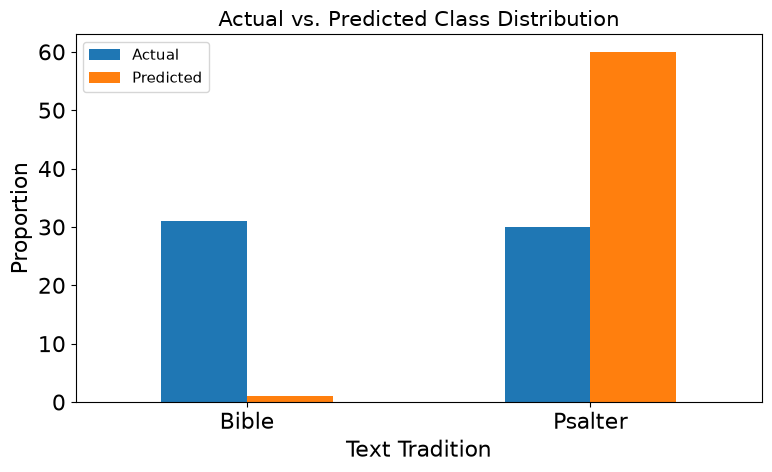

In [229]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Select your features and target
X = psalms[features]
y = psalms["text_Psalter"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = Perceptron(max_iter=100, eta0=0.1, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Compare actual and predicted class distributions
bias_df = pd.DataFrame({
    "Actual": y_test.value_counts(normalize=False),
    "Predicted": pd.Series(y_pred).value_counts(normalize=False)
}).fillna(0)

bias_df.index = bias_df.index.map({0: "Bible", 1: "Psalter"})
display(bias_df)

bias_df.plot(kind="bar", figsize=(8, 5))
plt.title("Actual vs. Predicted Class Distribution", fontsize=15)
plt.ylabel("Proportion")
plt.xlabel("Text Tradition")
plt.xticks(rotation=0)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

---
## Looking at Other Models

In [160]:

import pandas as pd

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Your five best features
target_features = [
    "subjectivity",
    "compound",
    "vader_category_Positive",
    "neu",
    "emotional_score"
]

# Predictor variables and target
X = psalms[target_features]
y = psalms["text_Psalter"]

# Stratified train-test split for final evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Define the three models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    ),

    "Linear SVM": make_pipeline(
        StandardScaler(),
        LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=42
        )
    ),

    "MLP Neural Network": make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(8,),
            activation="relu",
            solver="adam",
            alpha=0.01,
            max_iter=2000,
            early_stopping=True,
            random_state=42
        )
    )
}

# Five-fold stratified cross-validation on training data
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy"
}

results = []
trained_models = {}

for name, model in models.items():

    # Cross-validation using training data only
    cv_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    # Fit on the entire training set
    model.fit(X_train, y_train)
    trained_models[name] = model

    # Evaluate on the held-out test set
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "CV Accuracy": cv_scores["test_accuracy"].mean(),
        "CV Accuracy SD": cv_scores["test_accuracy"].std(),
        "CV F1": cv_scores["test_f1"].mean(),
        "CV Balanced Accuracy":
            cv_scores["test_balanced_accuracy"].mean(),
        "Test Accuracy": accuracy_score(y_test, y_pred)
    })

# Display results, best cross-validation accuracy first
results_df = pd.DataFrame(results).sort_values(
    "CV Accuracy",
    ascending=False
)

print(results_df.to_string(index=False))


              Model  CV Accuracy  CV Accuracy SD    CV F1  CV Balanced Accuracy  Test Accuracy
Logistic Regression     0.529167        0.136040 0.531539              0.529167       0.459016
         Linear SVM     0.529167        0.128830 0.537584              0.529167       0.475410
 MLP Neural Network     0.454167        0.082706 0.429458              0.454167       0.590164


In [161]:

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Bible", "Psalter"],
        zero_division=0
    ))



Logistic Regression

Confusion Matrix:
[[11 20]
 [13 17]]

Classification Report:
              precision    recall  f1-score   support

       Bible       0.46      0.35      0.40        31
     Psalter       0.46      0.57      0.51        30

    accuracy                           0.46        61
   macro avg       0.46      0.46      0.45        61
weighted avg       0.46      0.46      0.45        61


Linear SVM

Confusion Matrix:
[[12 19]
 [13 17]]

Classification Report:
              precision    recall  f1-score   support

       Bible       0.48      0.39      0.43        31
     Psalter       0.47      0.57      0.52        30

    accuracy                           0.48        61
   macro avg       0.48      0.48      0.47        61
weighted avg       0.48      0.48      0.47        61


MLP Neural Network

Confusion Matrix:
[[23  8]
 [17 13]]

Classification Report:
              precision    recall  f1-score   support

       Bible       0.57      0.74      0.65        3